a =  0.8920484860803973  b =  -8.388949997247533


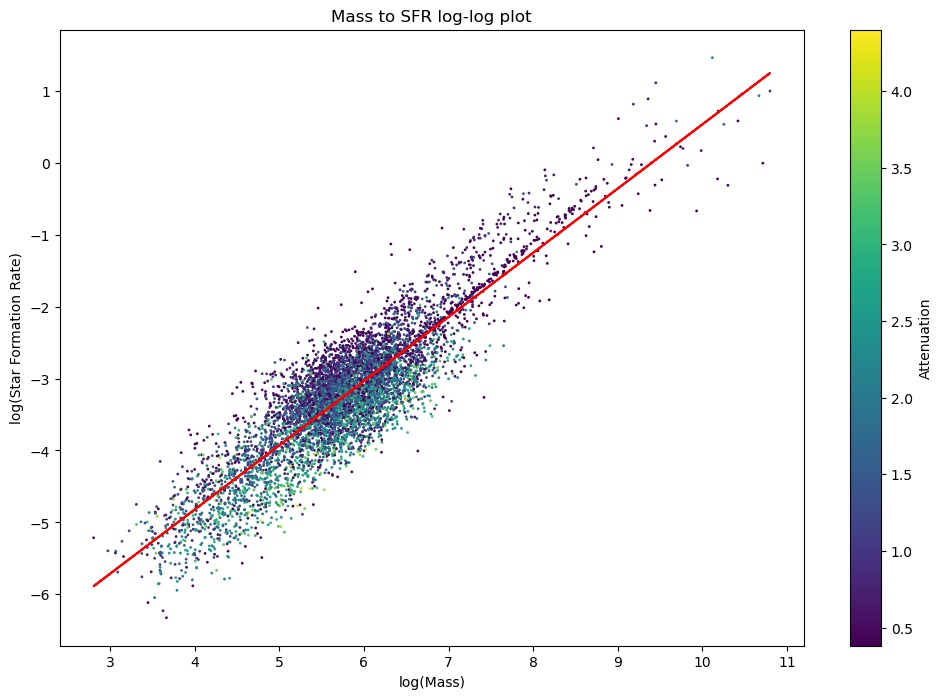

In [ ]:
from astropy.io import fits
from astropy.table import Table
import matplotlib.pyplot as plt
import numpy as np

results = fits.open('results.fits')

table = Table(results[1].data)

mass = table['bayes.stellar.m_star']
sfr = table['bayes.sfh.sfr']
attenuation = table['bayes.attenuation.Av_BC']

log_mass = np.log10(mass)
log_sfr = np.log10(sfr)

a, b = np.polyfit(log_mass, log_sfr, 1)

linear_fit = a*log_mass + b

print("a = ", a, " b = ",  b)

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit, color = "red")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()

I got a linear fit with: a =0.892, b =-8.389

The formula from Speagle 2014 is:

$$
\log \psi(M^*, t) = 
\big(0.96 \pm 0.05 - (0.045 \pm 0.006) \cdot t \big) \log M^* 
- \big(7.41 \pm 0.48 - (0.27 \pm 0.06) \cdot t \big)
$$

I will derive t from redshift median from my probe:

Age of the Universe at median z=0.200 is 11.275 Gyr


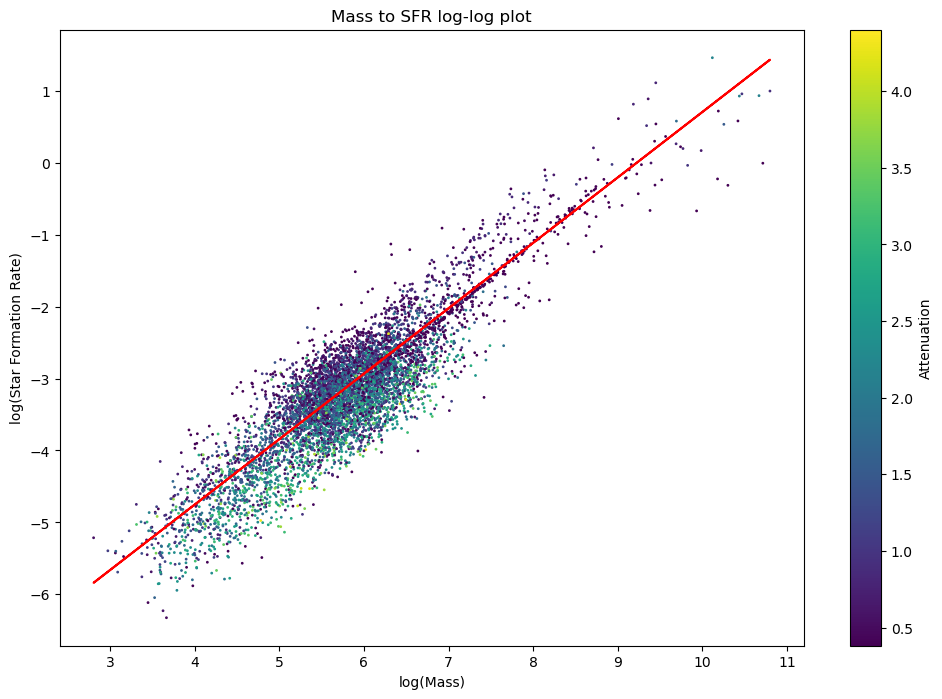

In [17]:
import statistics
from astropy.cosmology import Planck18

redshift = table['bayes.universe.redshift']
redshift_median = statistics.median(redshift)

t = Planck18.age(redshift_median)

print(f"Age of the Universe at median z={redshift_median:.3f} is {t:.3f}")

a2 = 0.96 - 0.0045 * t.value
b2 = 7.41 - 0.027 * t.value

linear_fit2 = a2 * log_mass + b

plt.figure(figsize=(12, 8)) 
scatter = plt.scatter(log_mass, log_sfr, s=1, c=attenuation, cmap='viridis')
cbar = plt.colorbar(scatter)  
cbar.set_label('Attenuation')
plt.plot(log_mass, linear_fit2, color = "red")
plt.xlabel('log(Mass)')
plt.ylabel('log(Star Formation Rate)')
plt.title('Mass to SFR log-log plot')
plt.show()